# Automobile Data Cleaning, String Manipulation, and Neon PostgreSQL
**Contribution:** Senay — Data Cleaning

This notebook inspects and cleans a used-car dataset through duplicate removal,
text normalization, measurement extraction, missing-value treatment, and
validation. The processed dataset is exported as one CSV and uploaded using
the project's existing Neon database connection class.

**Dataset:** [Vehicle dataset — Nehal Birla, Kaggle](https://www.kaggle.com/datasets/nehalbirla/vehicle-dataset-from-cardekho),
originally `Car details v3.csv`, stored locally as `car_details_v3.csv`.
The original dataset has 8,128 records and 13 columns. Prices are historical
advertised selling prices in Indian rupees (INR).


## 1. Imports and project paths
The notebook is located in `notebooks/`. It reads the single source file at
`../data/raw/car_details_v3.csv`. The project root contains `data/`, `src/`,
and the private database configuration file `.env`.

All libraries required by the cleaning cells are imported here. The source CSV
is preserved; the only exported data file is `data/processed/cars_cleaned.csv`.


In [1]:
from pathlib import Path
from datetime import datetime, timezone
import os
import sys

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.impute import SimpleImputer

RAW_PATH = Path("../data/raw/car_details_v3.csv")
PROJECT_ROOT = Path("..").resolve()
PROCESSED = PROJECT_ROOT / "data" / "processed"

if not RAW_PATH.is_file():
    raise FileNotFoundError(f"Dataset not found: {RAW_PATH.resolve()}")

PROCESSED.mkdir(parents=True, exist_ok=True)
if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))

pd.set_option("display.max_columns", 36)
print("Source file:", RAW_PATH.resolve())


Source file: /workspace/scratch/fa84e22f4adc/upload/Car details v3.csv


## 2. Load and inspect the original data
`cars_raw` stores the source data loaded from CSV. Inspection covers dimensions,
column names, data types, sample observations, and descriptive statistics.
A `source_row` field is added later to the working copy for traceability.


In [2]:
cars_raw = pd.read_csv(RAW_PATH)
required_columns = ["name", "year", "selling_price", "km_driven", "fuel", "seller_type",
                    "transmission", "owner", "mileage", "engine", "max_power", "torque", "seats"]
if list(cars_raw.columns) != required_columns:
    raise ValueError("Unexpected source columns; review this version before cleaning.")
print("Rows and columns:", cars_raw.shape)
display(cars_raw.head())
cars_raw.info()
display(cars_raw.describe(include="all").T)


Rows and columns: (8128, 13)


,name,year,selling_price,km_driven,fuel,seller_type,transmission,owner,mileage,engine,max_power,torque,seats
0,Maruti Swift Dzire VDI,2014,450000,145500,Diesel,Individual,Manual,First Owner,23.4 kmpl,1248 CC,74 bhp,190Nm@ 2000rpm,5.0
1,Skoda Rapid 1.5 TDI Ambition,2014,370000,120000,Diesel,Individual,Manual,Second Owner,21.14 kmpl,1498 CC,103.52 bhp,250Nm@ 1500-2500rpm,5.0
2,Honda City 2017-2020 EXi,2006,158000,140000,Petrol,Individual,Manual,Third Owner,17.7 kmpl,1497 CC,78 bhp,"12.7@ 2,700(kgm@ rpm)",5.0
3,Hyundai i20 Sportz Diesel,2010,225000,127000,Diesel,Individual,Manual,First Owner,23.0 kmpl,1396 CC,90 bhp,22.4 kgm at 1750-2750rpm,5.0
4,Maruti Swift VXI BSIII,2007,130000,120000,Petrol,Individual,Manual,First Owner,16.1 kmpl,1298 CC,88.2 bhp,"11.5@ 4,500(kgm@ rpm)",5.0


,count,unique,top,freq,mean,std,min,25%,50%,75%,max
name,8128,2058,Maruti Swift Dzire VDI,129,NaN,NaN,NaN,NaN,NaN,NaN,NaN
year,8128.0,NaN,NaN,NaN,2013.804011,4.044249,1983.0,2011.0,2015.0,2017.0,2020.0
selling_price,8128.0,NaN,NaN,NaN,638271.807702,806253.403508,29999.0,254999.0,450000.0,675000.0,10000000.0
km_driven,8128.0,NaN,NaN,NaN,69819.510827,56550.554958,1.0,35000.0,60000.0,98000.0,2360457.0
fuel,8128,4,Diesel,4402,NaN,NaN,NaN,NaN,NaN,NaN,NaN
seller_type,8128,3,Individual,6766,NaN,NaN,NaN,NaN,NaN,NaN,NaN
transmission,8128,2,Manual,7078,NaN,NaN,NaN,NaN,NaN,NaN,NaN
owner,8128,5,First Owner,5289,NaN,NaN,NaN,NaN,NaN,NaN,NaN
mileage,7907,393,18.9 kmpl,225,NaN,NaN,NaN,NaN,NaN,NaN,NaN
engine,7907,121,1248 CC,1017,NaN,NaN,NaN,NaN,NaN,NaN,NaN


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 8128 entries, 0 to 8127
Data columns (total 13 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   name           8128 non-null   object 
 1   year           8128 non-null   int64  
 2   selling_price  8128 non-null   int64  
 3   km_driven      8128 non-null   int64  
 4   fuel           8128 non-null   object 
 5   seller_type    8128 non-null   object 
 6   transmission   8128 non-null   object 
 7   owner          8128 non-null   object 
 8   mileage        7907 non-null   object 
 9   engine         7907 non-null   object 
 10  max_power      7913 non-null   object 
 11  torque         7906 non-null   object 
 12  seats          7907 non-null   float64
dtypes: float64(1), int64(3), object(9)
memory usage: 825.6+ KB


,count,unique,top,freq,mean,std,min,25%,50%,75%,max
name,8128,2058,Maruti Swift Dzire VDI,129,NaN,NaN,NaN,NaN,NaN,NaN,NaN
year,8128.0,NaN,NaN,NaN,2013.804011,4.044249,1983.0,2011.0,2015.0,2017.0,2020.0
selling_price,8128.0,NaN,NaN,NaN,638271.807702,806253.403508,29999.0,254999.0,450000.0,675000.0,10000000.0
km_driven,8128.0,NaN,NaN,NaN,69819.510827,56550.554958,1.0,35000.0,60000.0,98000.0,2360457.0
fuel,8128,4,Diesel,4402,NaN,NaN,NaN,NaN,NaN,NaN,NaN
seller_type,8128,3,Individual,6766,NaN,NaN,NaN,NaN,NaN,NaN,NaN
transmission,8128,2,Manual,7078,NaN,NaN,NaN,NaN,NaN,NaN,NaN
owner,8128,5,First Owner,5289,NaN,NaN,NaN,NaN,NaN,NaN,NaN
mileage,7907,393,18.9 kmpl,225,NaN,NaN,NaN,NaN,NaN,NaN,NaN
engine,7907,121,1248 CC,1017,NaN,NaN,NaN,NaN,NaN,NaN,NaN


### Data dictionary

| Column | Meaning | Treatment |
|---|---|---|
| name | Manufacturer, model, and variant | Keep raw; normalize whitespace; derive brand/model |
| year | Listed vehicle year | Validate; retain |
| selling_price | Listed selling price, INR | Validate positive; retain |
| km_driven | Total distance travelled, kilometres | Validate nonnegative; retain |
| fuel | Petrol, Diesel, CNG, or LPG | Standardize text case |
| seller_type | Seller category | Standardize text case and spacing |
| transmission | Manual or Automatic | Standardize text case and spacing |
| owner | Ownership category | Standardize text case and spacing |
| mileage | Fuel economy, not odometer distance | Extract value and unit separately |
| engine | Engine displacement with CC suffix | Derive numeric engine_cc |
| max_power | Engine power with bhp suffix | Derive numeric max_power_bhp |
| torque | Torque and RPM in inconsistent formats | Preserve; normalize spacing for inspection |
| seats | Seating capacity | Fill missing values using a categorical strategy |

Torque parsing is not forced into a single numeric value: the strings mix
units and RPM ranges. The raw field and `torque_text` remain available; missing
torque values are reported rather than invented.


## 3. Assess missing values and duplicates
`isna()` counts missing entries; `notna()` confirms valid values. Counts below
describe the original data before any rows are excluded.


In [17]:
missing_before = pd.DataFrame({
    "missing_count": cars_raw.isna().sum(),
    "missing_percent": (cars_raw.isna().mean() * 100).round(2),
    "non_missing_count": cars_raw.notna().sum(),
})
display(missing_before)
print("Repeated rows after the first occurrence:", cars_raw.duplicated().sum())
display(cars_raw.loc[cars_raw.duplicated(keep=False)].head(6))


,missing_count,missing_percent,non_missing_count
name,0,0.00,8128
year,0,0.00,8128
selling_price,0,0.00,8128
km_driven,0,0.00,8128
fuel,0,0.00,8128
seller_type,0,0.00,8128
transmission,0,0.00,8128
owner,0,0.00,8128
mileage,221,2.72,7907
engine,221,2.72,7907


Repeated rows after the first occurrence: 1202


,name,year,selling_price,km_driven,fuel,seller_type,transmission,owner,mileage,engine,max_power,torque,seats
31,Fiat Palio 1.2 ELX,2003,70000,50000,Petrol,Individual,Manual,Second Owner,NaN,NaN,NaN,NaN,NaN
32,Maruti Omni 8 Seater BSIV,2012,150000,35000,Petrol,Individual,Manual,Second Owner,14.0 kmpl,796 CC,35 bhp,6.1kgm@ 3000rpm,5.0
33,Hyundai i20 1.2 Asta Dual Tone,2018,730000,2388,Petrol,Individual,Manual,First Owner,18.6 kmpl,1197 CC,81.83 bhp,114.7Nm@ 4000rpm,5.0
34,Maruti Vitara Brezza LDi,2017,650000,16200,Diesel,Individual,Manual,First Owner,24.3 kmpl,1248 CC,88.5 bhp,200Nm@ 1750rpm,5.0
35,Maruti Alto 800 CNG LXI Optional,2019,330000,10000,CNG,Individual,Manual,Second Owner,33.44 km/kg,796 CC,40.3 bhp,60Nm@ 3500rpm,4.0
36,Maruti Alto K10 VXI Airbag,2019,366000,15000,Petrol,Individual,Manual,First Owner,23.95 kmpl,998 CC,67.1 bhp,90Nm@ 3500rpm,5.0


## 4. Create a working copy and treat repeated rows
Exact repeated records are treated as duplicate listings, with one occurrence
retained. There is no VIN or listing ID, so matching attributes do not establish
vehicle identity. The original CSV remains available for comparison.

Duplicate detection uses the original 13 columns before adding `source_row`.
Excluded duplicate records are held in memory for row-accounting checks, not
exported as another raw-data file or uploaded to a raw-data table.


In [18]:
# Remove Duplicate Records and Create the Working Copy

duplicate_mask = cars_raw.duplicated(keep="first")

# Retained in memory for the existing validation checks.
duplicate_rows = cars_raw.loc[duplicate_mask].copy()

cars_clean = cars_raw.loc[~duplicate_mask].copy()

# Preserve each retained record's original row position.
cars_clean.insert(0, "source_row", cars_clean.index + 1)

print("Original records:", len(cars_raw))
print("Duplicates removed:", len(duplicate_rows))
print("Retained records:", len(cars_clean))

Original records: 8128
Duplicates removed: 1202
Retained records: 6926


## 5. Clean text and extract manufacturer/model
String operations include `.str.strip()`, `.str.replace()`, `.str.lower()`,
`.str.upper()`, `.str.extract()`, and `.str.contains()`. They normalize spaces
and case, extract manufacturers/models, and select matching text patterns.
Original text columns remain available for comparison.

Multiword manufacturers such as Land Rover and Ashok Leyland are handled
explicitly rather than split at the first space.


In [19]:
def tidy_text(series):
    return series.astype("string").str.strip().str.replace(r"\s+", " ", regex=True)

cars_clean["name_clean"] = tidy_text(cars_clean["name"])
cars_clean["fuel_clean"] = tidy_text(cars_clean["fuel"]).str.upper()
cars_clean["seller_type_clean"] = tidy_text(cars_clean["seller_type"]).str.lower()
cars_clean["transmission_clean"] = tidy_text(cars_clean["transmission"]).str.lower()
cars_clean["owner_clean"] = tidy_text(cars_clean["owner"]).str.lower()
cars_clean["torque_text"] = tidy_text(cars_clean["torque"]).str.lower()

brand_pattern = r"^(Land Rover|Ashok Leyland|\S+)\s*(.*)$"
parts = cars_clean["name_clean"].str.extract(brand_pattern)
cars_clean["brand"] = parts[0]
cars_clean["model"] = parts[1].str.strip()
display(cars_clean[["name", "brand", "model", "fuel_clean"]].head())
display(cars_clean.loc[cars_clean["name_clean"].str.contains(
    r"^(?:Land Rover|Ashok Leyland)\b", regex=True, na=False), ["name", "brand", "model"]])


,name,brand,model,fuel_clean
0,Maruti Swift Dzire VDI,Maruti,Swift Dzire VDI,DIESEL
1,Skoda Rapid 1.5 TDI Ambition,Skoda,Rapid 1.5 TDI Ambition,DIESEL
2,Honda City 2017-2020 EXi,Honda,City 2017-2020 EXi,PETROL
3,Hyundai i20 Sportz Diesel,Hyundai,i20 Sportz Diesel,DIESEL
4,Maruti Swift VXI BSIII,Maruti,Swift VXI BSIII,PETROL


,name,brand,model
135,Land Rover Discovery Sport TD4 SE,Land Rover,Discovery Sport TD4 SE
2137,Land Rover Freelander 2 TD4 HSE,Land Rover,Freelander 2 TD4 HSE
4011,Ashok Leyland Stile LE,Ashok Leyland,Stile LE
6724,Land Rover Range Rover Evoque 2.2L Pure,Land Rover,Range Rover Evoque 2.2L Pure


## 6. Convert engine capacity and power strings to numbers
`pd.to_numeric(errors="coerce")` converts invalid numeric text to a missing
value. A power entry containing only `bhp` is missing information, not zero.
A zero power or zero fuel-economy value is treated as an invalid placeholder
for an operating car and is changed to missing in the derived numeric field.
Original values and Boolean flags preserve the evidence.


In [20]:
engine_text = tidy_text(cars_clean["engine"]).str.lower()
power_text = tidy_text(cars_clean["max_power"]).str.lower()
cars_clean["engine_cc"] = pd.to_numeric(
    engine_text.str.replace("cc", "", regex=False).str.strip(), errors="coerce").astype("float64")
cars_clean["max_power_bhp"] = pd.to_numeric(
    power_text.str.replace("bhp", "", regex=False).str.strip(), errors="coerce").astype("float64")
cars_clean["engine_invalid_nonpositive"] = cars_clean["engine_cc"].le(0)
cars_clean["power_invalid_nonpositive"] = cars_clean["max_power_bhp"].le(0)
cars_clean.loc[cars_clean["engine_invalid_nonpositive"], "engine_cc"] = np.nan
cars_clean.loc[cars_clean["power_invalid_nonpositive"], "max_power_bhp"] = np.nan
display(cars_clean[["engine", "engine_cc", "max_power", "max_power_bhp"]].head())
print("Missing power after parsing:", cars_clean["max_power_bhp"].isna().sum())


,engine,engine_cc,max_power,max_power_bhp
0,1248 CC,1248.0,74 bhp,74.00
1,1498 CC,1498.0,103.52 bhp,103.52
2,1497 CC,1497.0,78 bhp,78.00
3,1396 CC,1396.0,90 bhp,90.00
4,1298 CC,1298.0,88.2 bhp,88.20


Missing power after parsing: 209


## 7. Separate fuel economy values from their units
`kmpl` means kilometres per litre; `km/kg` means kilometres per kilogram.
These units are not directly interchangeable and are never averaged together.
A full-string pattern rejects unrecognized measurements instead of silently
extracting an unrelated number.

For a missing unit, use a fuel-to-unit mapping only where the observed data
contains exactly one unit for that fuel. Such inferred units are flagged.


In [21]:
mileage_text = tidy_text(cars_clean["mileage"]).str.lower()
mileage_parts = mileage_text.str.extract(r"^(\d+(?:\.\d+)?)\s*(kmpl|km/kg)$")
cars_clean["fuel_economy_value"] = pd.to_numeric(mileage_parts[0], errors="coerce").astype("float64")
cars_clean["fuel_economy_unit"] = mileage_parts[1].astype("string")
cars_clean["economy_invalid_nonpositive"] = cars_clean["fuel_economy_value"].le(0)
cars_clean.loc[cars_clean["economy_invalid_nonpositive"], "fuel_economy_value"] = np.nan
observed_unit_counts = cars_clean.groupby("fuel_clean")["fuel_economy_unit"].nunique()
single_unit_fuels = observed_unit_counts[observed_unit_counts.eq(1)].index
unit_lookup = (cars_clean.loc[cars_clean["fuel_clean"].isin(single_unit_fuels)]
               .dropna(subset=["fuel_economy_unit"])
               .groupby("fuel_clean")["fuel_economy_unit"].first())
missing_unit = cars_clean["fuel_economy_unit"].isna()
inferred_units = cars_clean["fuel_clean"].map(unit_lookup)
cars_clean["fuel_economy_unit_inferred"] = missing_unit & inferred_units.notna()
cars_clean["fuel_economy_unit"] = cars_clean["fuel_economy_unit"].fillna(inferred_units)
display(cars_clean[["mileage", "fuel_economy_value", "fuel_economy_unit"]].head(10))
display(pd.crosstab(cars_clean["fuel_clean"], cars_clean["fuel_economy_unit"]))


,mileage,fuel_economy_value,fuel_economy_unit
0,23.4 kmpl,23.40,kmpl
1,21.14 kmpl,21.14,kmpl
2,17.7 kmpl,17.70,kmpl
3,23.0 kmpl,23.00,kmpl
4,16.1 kmpl,16.10,kmpl
5,20.14 kmpl,20.14,kmpl
6,17.3 km/kg,17.30,km/kg
7,16.1 kmpl,16.10,kmpl
8,23.59 kmpl,23.59,kmpl
9,20.0 kmpl,20.00,kmpl


fuel_economy_unit,km/kg,kmpl
fuel_clean,,
CNG,56,0
DIESEL,0,3755
LPG,38,0
PETROL,0,3077


## 8. Validate essential numerical fields
Year, price, distance, and seat count are converted to numbers. Essential-field
checks require a plausible integer year, positive price, and nonnegative integer
odometer value. Rows failing these checks are excluded and counted in memory.
No separate invalid-row CSV is generated. Invalid seat counts become missing
for the later imputation step.


In [22]:
for col in ["year", "selling_price", "km_driven", "seats"]:
    cars_clean[col] = pd.to_numeric(cars_clean[col], errors="coerce")

current_year = datetime.now(timezone.utc).year
valid_essential = (
    cars_clean["year"].between(1886, current_year + 1)
    & cars_clean["year"].mod(1).eq(0)
    & cars_clean["selling_price"].gt(0)
    & cars_clean["km_driven"].ge(0)
    & cars_clean["km_driven"].mod(1).eq(0)
).fillna(False)

invalid_rows = cars_clean.loc[~valid_essential].copy()
cars_clean = cars_clean.loc[valid_essential].copy()
cars_clean["year"] = cars_clean["year"].astype("int64")
cars_clean["km_driven"] = cars_clean["km_driven"].astype("int64")

valid_seats = cars_clean["seats"].gt(0) & cars_clean["seats"].mod(1).eq(0)
cars_clean.loc[~valid_seats, "seats"] = np.nan
print("Rows excluded by essential-field checks:", len(invalid_rows))


Rows excluded by essential-field checks: 0


## 9. Compare missing-value strategies before choosing
`dropna()` can discard observations, and `dropna(axis=1)` can discard useful
features. Mean imputation is sensitive to extreme values. Median imputation
uses a central observed value and is suitable here for skewed measurements.
Mode is appropriate for discrete seat counts. These are demonstrations on
copies; the final strategy is implemented in the following section.
`SimpleImputer` also demonstrates a reusable scikit-learn median strategy.


In [23]:
before_imputation = cars_clean.copy()
numeric_fields = ["engine_cc", "max_power_bhp", "fuel_economy_value", "seats"]
display(before_imputation[numeric_fields].isna().sum().rename("missing_before_imputation"))
comparison = pd.DataFrame([
    {"strategy": "Keep all rows", "rows_retained": len(before_imputation)},
    {"strategy": "Drop rows missing any selected numeric field",
     "rows_retained": len(before_imputation.dropna(subset=numeric_fields))},
])
display(comparison)
print("Columns if every column with missing data were dropped:",
      before_imputation.dropna(axis=1).shape[1], "of", before_imputation.shape[1])
engine_mean_demo = before_imputation["engine_cc"].fillna(before_imputation["engine_cc"].mean())
engine_median_demo = before_imputation["engine_cc"].fillna(before_imputation["engine_cc"].median())
seat_mode = before_imputation["seats"].mode().iloc[0]
seats_mode_demo = before_imputation["seats"].fillna(seat_mode)
simple_imputer = SimpleImputer(strategy="median")
simple_engine_demo = simple_imputer.fit_transform(before_imputation[["engine_cc"]]).ravel()
display(pd.DataFrame({
    "engine_original": before_imputation["engine_cc"],
    "engine_mean_demo": engine_mean_demo,
    "engine_median_demo": engine_median_demo,
    "engine_simple_imputer_demo": simple_engine_demo,
    "seats_mode_demo": seats_mode_demo,
}).loc[before_imputation["engine_cc"].isna()].head())
print("Overall engine mean / median:", round(before_imputation["engine_cc"].mean(), 2),
      before_imputation["engine_cc"].median())


engine_cc             208
max_power_bhp         209
fuel_economy_value    223
seats                 208
Name: missing_before_imputation, dtype: int64

,strategy,rows_retained
0,Keep all rows,6926
1,Drop rows missing any selected numeric field,6702


Columns if every column with missing data were dropped: 21 of 30


,engine_original,engine_mean_demo,engine_median_demo,engine_simple_imputer_demo,seats_mode_demo
13,NaN,1430.891337,1248.0,1248.0,5.0
31,NaN,1430.891337,1248.0,1248.0,5.0
78,NaN,1430.891337,1248.0,1248.0,5.0
87,NaN,1430.891337,1248.0,1248.0,5.0
119,NaN,1430.891337,1248.0,1248.0,5.0


,engine_original,engine_mean_demo,engine_median_demo,engine_simple_imputer_demo,seats_mode_demo
13,NaN,1430.891337,1248.0,1248.0,5.0
31,NaN,1430.891337,1248.0,1248.0,5.0
78,NaN,1430.891337,1248.0,1248.0,5.0
87,NaN,1430.891337,1248.0,1248.0,5.0
119,NaN,1430.891337,1248.0,1248.0,5.0


Overall engine mean / median: 1430.89 1248.0


## 10. Apply and flag the selected imputation strategy
Engine capacity and power use manufacturer-and-fuel medians, with fuel-median
and overall-median fallbacks. Fuel economy uses manufacturer/fuel/unit groups,
followed by fuel/unit and unit groups. It never uses a median that mixes
kilometres per litre with kilometres per kilogram.

Seats use manufacturer modes with an overall-mode fallback. Tied modes are
resolved deterministically using the smallest mode. Imputation flags identify
estimated measurements. In later predictive modelling, these statistics would
be estimated from training data only to prevent data leakage.


In [24]:
def hierarchical_median(frame, column, levels):
    result = frame[column].copy()
    for group_columns in levels:
        estimates = frame.groupby(group_columns, dropna=False)[column].transform("median")
        result = result.fillna(estimates)
    return result

for col in ["engine_cc", "max_power_bhp"]:
    missing = cars_clean[col].isna()
    filled = hierarchical_median(cars_clean, col, [["brand", "fuel_clean"], ["fuel_clean"]])
    cars_clean[col] = filled.fillna(cars_clean[col].median())
    cars_clean[col + "_imputed"] = missing & cars_clean[col].notna()

missing_economy = cars_clean["fuel_economy_value"].isna()
cars_clean["fuel_economy_value"] = hierarchical_median(
    cars_clean, "fuel_economy_value", [
        ["brand", "fuel_clean", "fuel_economy_unit"],
        ["fuel_clean", "fuel_economy_unit"], ["fuel_economy_unit"],
    ])
cars_clean["fuel_economy_value_imputed"] = missing_economy & cars_clean["fuel_economy_value"].notna()

def smallest_mode(values):
    modes = values.mode()
    return modes.iloc[0] if not modes.empty else np.nan

missing_seats = cars_clean["seats"].isna()
cars_clean["seats_count"] = (cars_clean["seats"].fillna(
    cars_clean.groupby("brand")["seats"].transform(smallest_mode)
).fillna(smallest_mode(cars_clean["seats"])).astype("int64"))
cars_clean["seats_count_imputed"] = missing_seats
final_numeric = ["engine_cc", "max_power_bhp", "fuel_economy_value", "seats_count"]
imputation_flags = [col + "_imputed" for col in final_numeric]
display(cars_clean[imputation_flags].sum().rename("values_imputed"))
display(cars_clean[["brand", "engine_cc", "max_power_bhp", "fuel_economy_value", "seats_count"]].head())


engine_cc_imputed             208
max_power_bhp_imputed         209
fuel_economy_value_imputed    223
seats_count_imputed           208
Name: values_imputed, dtype: int64

,brand,engine_cc,max_power_bhp,fuel_economy_value,seats_count
0,Maruti,1248.0,74.00,23.40,5
1,Skoda,1498.0,103.52,21.14,5
2,Honda,1497.0,78.00,17.70,5
3,Hyundai,1396.0,90.00,23.00,5
4,Maruti,1298.0,88.20,16.10,5


## 11. Inspect potential outliers without automatically deleting them
An IQR flag identifies values outside Q1 - 1.5*IQR to Q3 + 1.5*IQR. An expensive
luxury car can be a valid observation. Price outliers are retained; the flag
supports review and does not label records as errors.


In [25]:
q1, q3 = cars_clean["selling_price"].quantile([0.25, 0.75])
iqr = q3 - q1
lower_bound, upper_bound = q1 - 1.5 * iqr, q3 + 1.5 * iqr
cars_clean["price_iqr_flag"] = ~cars_clean["selling_price"].between(lower_bound, upper_bound)
print("Price IQR bounds (INR):", lower_bound, upper_bound)
print("Potential price outliers retained:", cars_clean["price_iqr_flag"].sum())
display(cars_clean.loc[cars_clean["price_iqr_flag"], ["brand", "model", "selling_price"]].head())


Price IQR bounds (INR): -325250.0 1208750.0
Potential price outliers retained: 328


,brand,model,selling_price
41,Jeep,Compass 1.4 Limited Plus BSIV,2100000
47,Toyota,Fortuner 4x4 MT,1500000
49,Mercedes-Benz,B Class B180,1450000
55,Toyota,Innova Crysta 2.8 ZX AT BSIV,1650000
57,Audi,A6 2.0 TDI Technology,1750000


## 12. Compare missing values and summarize the sample
The table compares missing counts on the same retained records before and after
imputation. Zero after-imputation counts indicate complete selected numerical
features; they do not establish that the estimated values are accurate.

The manufacturer chart describes this dataset's composition rather than market
share. Original source columns can still contain missing values because they
are preserved separately from their derived numerical features.


,Before imputation,After imputation,Values filled
engine_cc,208,0,208
max_power_bhp,209,0,209
fuel_economy_value,223,0,223
seats_count,208,0,208


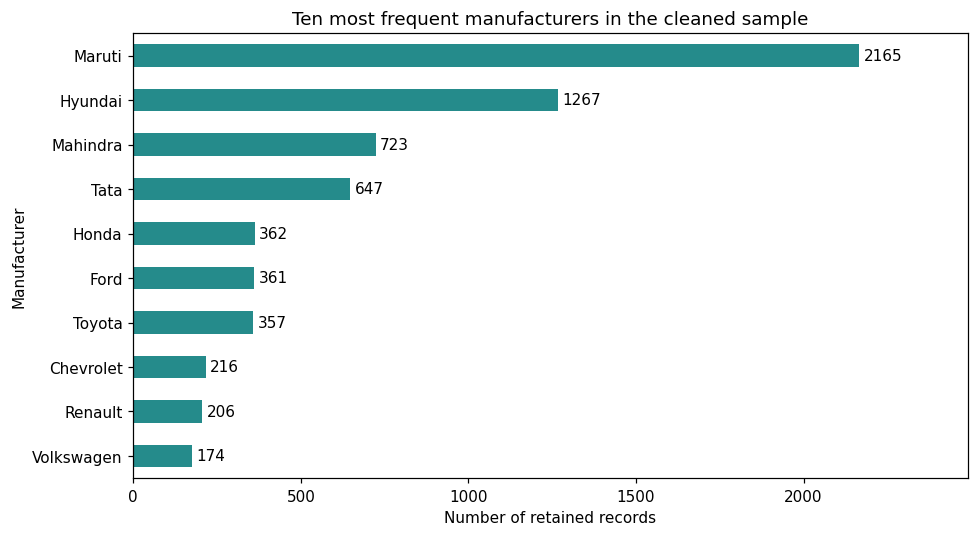

Most frequent manufacturer: Maruti with 2165 records
Missing selected numerical values: 0


In [26]:
before_counts = before_imputation[
    ["engine_cc", "max_power_bhp", "fuel_economy_value", "seats"]
].isna().sum()
before_counts.index = final_numeric
after_counts = cars_clean[final_numeric].isna().sum()

missing_comparison = pd.DataFrame({
    "Before imputation": before_counts,
    "After imputation": after_counts,
    "Values filled": cars_clean[imputation_flags].sum().to_numpy(),
})
display(missing_comparison)

brand_counts = cars_clean["brand"].value_counts().head(10)
ax = brand_counts.sort_values().plot.barh(figsize=(9, 5), color="#258b8b")
ax.set(
    title="Ten most frequent manufacturers in the cleaned sample",
    xlabel="Number of retained records",
    ylabel="Manufacturer",
)
for bars in ax.containers:
    ax.bar_label(bars, padding=3)
ax.margins(x=0.15)
plt.tight_layout()
plt.show()

print("Most frequent manufacturer:", brand_counts.index[0],
      "with", int(brand_counts.iloc[0]), "records")
print("Missing selected numerical values:", int(after_counts.sum()))


## 13. Validate and export one cleaned CSV
Validation checks row accounting, retained-record lineage, numerical
completeness, positive derived measurements, discrete seat counts, and
fuel-economy unit consistency. The validated data is exported to
`data/processed/cars_cleaned.csv`.


In [27]:
assert len(cars_clean) + len(duplicate_rows) + len(invalid_rows) == len(cars_raw)
assert cars_clean["source_row"].is_unique
assert not cars_clean[required_columns].duplicated().any()
assert cars_clean[final_numeric].notna().all().all()
assert np.isfinite(cars_clean[final_numeric].to_numpy(dtype=float)).all()
assert cars_clean[final_numeric].gt(0).all().all()
assert cars_clean["fuel_economy_unit"].notna().all()
assert cars_clean["fuel_economy_unit"].isin(["kmpl", "km/kg"]).all()
expected_units = cars_clean["fuel_clean"].map(unit_lookup)
assert expected_units.notna().all()
assert cars_clean["fuel_economy_unit"].eq(expected_units).all()
assert pd.api.types.is_integer_dtype(cars_clean["seats_count"])
assert cars_clean.loc[
    cars_clean["name_clean"].str.startswith("Land Rover", na=False), "brand"
].eq("Land Rover").all()

output_file = PROCESSED / "cars_cleaned.csv"
cars_clean.to_csv(output_file, index=False)

print("Validation passed.")
print("Original records:", len(cars_raw))
print("Exact repeats removed:", len(duplicate_rows))
print("Invalid essential records removed:", len(invalid_rows))
print("Cleaned rows and columns:", cars_clean.shape)
print("Export:", output_file.resolve())


Cleaned dataset saved: C:\Personal\Projects\cleaning-imputation-outliers\data\processed\cars_cleaned.csv
Rows and columns: (6926, 36)


## 14. Upload the processed CSV using the existing Neon connection
The processed CSV is read back from disk and uploaded through
`src.neon_connect.DatabaseManager`. A `SELECT 1` query verifies a live
connection before upload. The stored record count is compared with the CSV,
and sample records are retrieved for inspection.

Only `cardekho_clean` is written. `if_exists="replace"` refreshes this assignment
table on reruns, rather than appending duplicate copies. Configuration is read
from the private project-root `.env` file by the existing connection class.
A run without database configuration is explicitly reported as not executed.


In [28]:
processed_cars = pd.read_csv(output_file)
assert processed_cars.shape == cars_clean.shape
assert processed_cars["source_row"].tolist() == cars_clean["source_row"].tolist()

database_verified = False
database_configured = (
    (PROJECT_ROOT / ".env").is_file()
    or bool(os.getenv("DATABASE_URL"))
)

if not database_configured:
    print("Neon not executed: DATABASE_URL is not configured in this environment.")
else:
    from src.neon_connect import DatabaseManager

    db = DatabaseManager()
    try:
        connection_test = db.fetch_dataframe("SELECT 1 AS connection_test")
        assert int(connection_test.iloc[0, 0]) == 1
        print("Live Neon connection verified.")

        db.upload_dataframe(
            processed_cars,
            "cardekho_clean",
            if_exists="replace",
        )

        result = db.fetch_dataframe(
            "SELECT COUNT(*) AS total_rows FROM cardekho_clean"
        )
        assert int(result.loc[0, "total_rows"]) == len(processed_cars)
        display(result)
        display(db.fetch_dataframe(
            "SELECT * FROM cardekho_clean ORDER BY source_row LIMIT 5"
        ))

        database_verified = True
        print("Processed CSV uploaded and stored row count verified.")
    finally:
        db.engine.dispose()


✅ Successfully connected to Neon PostgreSQL database.
✅ Successfully uploaded 6926 rows to 'cardekho_clean'.


,total_rows
0,6926


,source_row,name,year,selling_price,km_driven,fuel,seller_type,transmission,owner,mileage,engine,max_power,torque,seats,name_clean,fuel_clean,seller_type_clean,transmission_clean,owner_clean,torque_text,brand,model,engine_cc,max_power_bhp,engine_invalid_nonpositive,power_invalid_nonpositive,fuel_economy_value,fuel_economy_unit,economy_invalid_nonpositive,fuel_economy_unit_inferred,engine_cc_imputed,max_power_bhp_imputed,fuel_economy_value_imputed,seats_count,seats_count_imputed,price_iqr_flag
0,1,Maruti Swift Dzire VDI,2014,450000,145500,Diesel,Individual,Manual,First Owner,23.4 kmpl,1248 CC,74 bhp,190Nm@ 2000rpm,5.0,Maruti Swift Dzire VDI,DIESEL,individual,manual,first owner,190nm@ 2000rpm,Maruti,Swift Dzire VDI,1248.0,74.00,False,False,23.40,kmpl,False,False,False,False,False,5,False,False
1,2,Skoda Rapid 1.5 TDI Ambition,2014,370000,120000,Diesel,Individual,Manual,Second Owner,21.14 kmpl,1498 CC,103.52 bhp,250Nm@ 1500-2500rpm,5.0,Skoda Rapid 1.5 TDI Ambition,DIESEL,individual,manual,second owner,250nm@ 1500-2500rpm,Skoda,Rapid 1.5 TDI Ambition,1498.0,103.52,False,False,21.14,kmpl,False,False,False,False,False,5,False,False
2,3,Honda City 2017-2020 EXi,2006,158000,140000,Petrol,Individual,Manual,Third Owner,17.7 kmpl,1497 CC,78 bhp,"12.7@ 2,700(kgm@ rpm)",5.0,Honda City 2017-2020 EXi,PETROL,individual,manual,third owner,"12.7@ 2,700(kgm@ rpm)",Honda,City 2017-2020 EXi,1497.0,78.00,False,False,17.70,kmpl,False,False,False,False,False,5,False,False
3,4,Hyundai i20 Sportz Diesel,2010,225000,127000,Diesel,Individual,Manual,First Owner,23.0 kmpl,1396 CC,90 bhp,22.4 kgm at 1750-2750rpm,5.0,Hyundai i20 Sportz Diesel,DIESEL,individual,manual,first owner,22.4 kgm at 1750-2750rpm,Hyundai,i20 Sportz Diesel,1396.0,90.00,False,False,23.00,kmpl,False,False,False,False,False,5,False,False
4,5,Maruti Swift VXI BSIII,2007,130000,120000,Petrol,Individual,Manual,First Owner,16.1 kmpl,1298 CC,88.2 bhp,"11.5@ 4,500(kgm@ rpm)",5.0,Maruti Swift VXI BSIII,PETROL,individual,manual,first owner,"11.5@ 4,500(kgm@ rpm)",Maruti,Swift VXI BSIII,1298.0,88.20,False,False,16.10,kmpl,False,False,False,False,False,5,False,False


## 15. Observations and reflection
The original dataset contains 8,128 records and 13 columns, with missing values
in five columns. Removing 1,202 exact repeats under the duplicate-listing
assumption leaves 6,926 records. All retained records pass the essential-field
checks. Text operations extract manufacturers/models, convert engine and power
measurements to numerical features, and separate fuel-economy values and units.

Group-based imputation fills 208 engine-capacity values, 209 power values,
223 fuel-economy values, and 208 seat counts. The selected derived numerical
features are complete, while original source fields remain available for
comparison. Imputation flags distinguish estimated from observed measurements.
The missing-value table documents this change directly. The manufacturer chart
shows Maruti is the most frequent brand in the retained sample; this does not
establish wider market share.

IQR flags identify 328 potentially unusual prices, which are retained because
a high price alone is not evidence of an error. The final dataset contains
6,926 rows and 36 columns, exported as a single cleaned CSV. The database cell
uploads that CSV to `cardekho_clean` and verifies its stored row count when
executed with the project's configured Neon connection.

Limitations include historical advertised prices, nonrepresentative listings,
uncertain duplicate identity, estimated missing measurements, and mixed torque
formats. Completeness is not equivalent to measurement accuracy, and the
imputed values should be considered when interpreting later analyses.
